# Quickstart: DWD ICON-EU forecast, 5 day, icosahedral - dynamical.org Icechunk Zarr

ICON-EU is the regional, high-resolution configuration of Deutscher Wetterdienst's (DWD) ICON numerical weather model. It produces 5-day forecasts covering Europe on a native triangular grid at ~6.5 km resolution, refreshed four times daily.

This dataset provides DWD ICON-EU 5-day forecasts from October 2026 to present, transformed into a single analysis-ready dataset by [dynamical.org](https://dynamical.org).

Dataset documentation: https://dynamical.org/catalog/dwd-icon-eu-forecast-5-day-icosahedral/

In [ ]:
# If running locally, follow README.md for simple dependency installation.
# If using Google Colab, run this cell.
!uv pip install dynamical-catalog xarray matplotlib cartopy geopandas shapely

In [2]:
# TEMPORARY: remove these lines once this dataset is in the production catalog.
# In staging for feedback, structure may change in breaking ways before promotion to prod.
import os
os.environ.setdefault("DYNAMICAL_STAC_CATALOG_URL", "https://stac-staging.dynamical.org/catalog.json")

import dynamical_catalog

ds = dynamical_catalog.open("dwd-icon-eu-forecast-5-day-icosahedral", chunks=None)
ds

<xarray.Dataset> Size: 929GB
Dimensions:                                             (init_time: 171,
                                                         lead_time: 93,
                                                         cell: 768608)
Coordinates:
  * init_time                                           (init_time) datetime64[ns] 1kB ...
    expected_forecast_length                            (init_time) timedelta64[us] 1kB ...
    ingested_forecast_length                            (init_time) timedelta64[us] 1kB ...
  * lead_time                                           (lead_time) timedelta64[us] 744B ...
    valid_time                                          (init_time, lead_time) datetime64[ns] 127kB ...
  * cell                                                (cell) int32 3MB 0 .....
    latitude                                            (cell) float32 3MB ...
    longitude                                           (cell) float32 3MB ...
    spatial_ref                                         int64 8B ...
Data variables: (12/19)
    cloud_cover_high                                    (init_time, lead_time, cell) float32 49GB ...
    convective_available_potential_energy_atmosphere    (init_time, lead_time, cell) float32 49GB ...
    dew_point_temperature_2m                            (init_time, lead_time, cell) float32 49GB ...
    cloud_cover_low                                     (init_time, lead_time, cell) float32 49GB ...
    cloud_cover_medium                                  (init_time, lead_time, cell) float32 49GB ...
    precipitation_surface                               (init_time, lead_time, cell) float32 49GB ...
    ...                                                  ...
    wind_u_10m                                          (init_time, lead_time, cell) float32 49GB ...
    snow_thickness_surface                              (init_time, lead_time, cell) float32 49GB ...
    total_cloud_cover_atmosphere                        (init_time, lead_time, cell) float32 49GB ...
    pressure_surface                                    (init_time, lead_time, cell) float32 49GB ...
    wind_gust_10m                                       (init_time, lead_time, cell) float32 49GB ...
    wind_v_10m                                          (init_time, lead_time, cell) float32 49GB ...
Attributes:
    dataset_id:           dwd-icon-eu-forecast-5-day-icosahedral
    dataset_version:      0.1.0
    name:                 DWD ICON-EU forecast, 5 day, icosahedral
    description:          High-resolution weather forecasts for Europe from t...
    attribution:          DWD ICON-EU data processed by dynamical.org.
    license:              CC-BY-4.0
    spatial_domain:       Europe
    spatial_resolution:   6.5 km
    time_domain:          Forecasts initialized 2026-10-07 00:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 6 hours
    forecast_domain:      Forecast lead time 0-120 hours (0-5 days) ahead
    forecast_resolution:  Forecast step 0-78 hours: hourly, 81-120 hours: 3 h...

This is a forecast dataset with two time dimensions: `init_time` (when the forecast run began) and `lead_time` (how far ahead the forecast extends). The `valid_time` coordinate combines these to give the actual forecasted time.

There is one spatial dimension, `cell`: `latitude` and `longitude` locate each triangle's centre, and the `mesh` group holds its corners. Forecast steps are hourly out to 78 hours and 3-hourly to 120 hours. Let's start with a forecast time series at a point, then a map at a single time step.

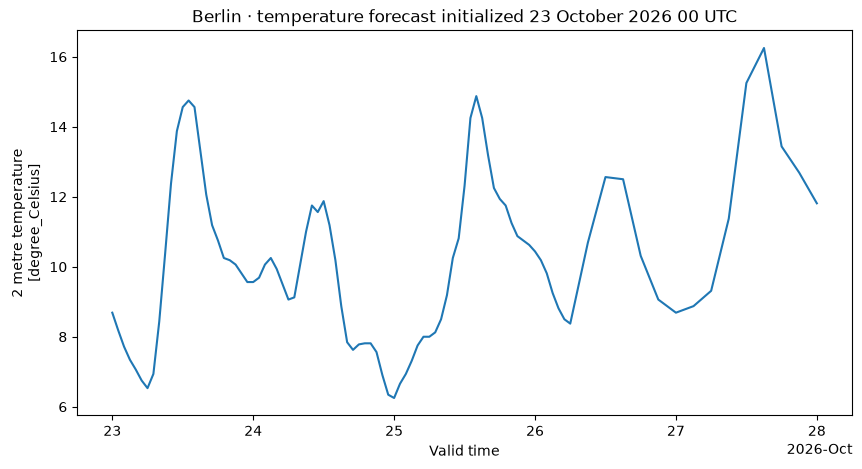

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Select the nearest cell centre to Berlin for a 5-day temperature forecast.
lat, lon = 52.52, 13.40
distance = (ds.latitude - lat) ** 2 + (
    (ds.longitude - lon) * np.cos(np.deg2rad(lat))
) ** 2
berlin_cell = int(distance.argmin("cell"))
plot_ds = ds["temperature_2m"].sel(init_time="2026-10-23T00").isel(cell=berlin_cell)
plot_ds.plot(x="valid_time", figsize=(10, 5))
plt.title("Berlin · temperature forecast initialized 23 October 2026 00 UTC");

Mean sea level pressure reveals the highs and lows that steer Europe's weather. [The Met Office issued amber wind warnings for the northern UK as Storm Boelo arrived on 24–25 October 2026](https://www.metoffice.gov.uk/about-us/news-and-media/media-centre/weather-and-climate-news/2026/amber-warning-issued-for-storm-boelo-as-storm-austen-moves-through). Here is the forecast for 25 October at 00 UTC, drawn directly on the native triangles.

In [4]:
mesh = dynamical_catalog.open("dwd-icon-eu-forecast-5-day-icosahedral", group="mesh", chunks=None).load()

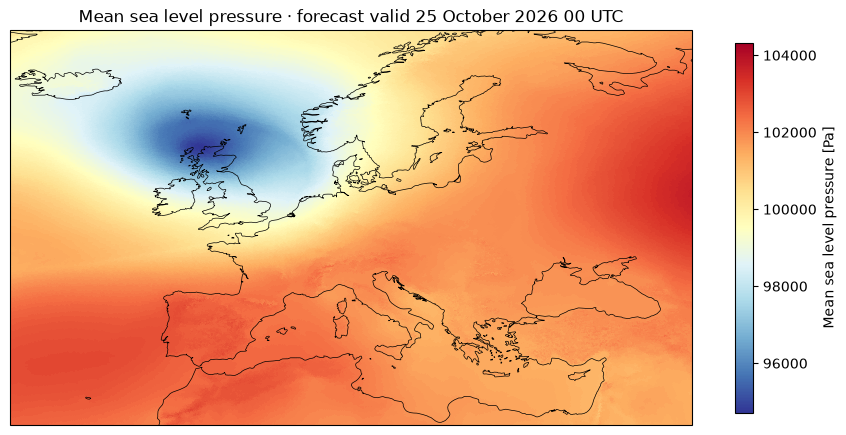

In [5]:
import cartopy.crs as ccrs

triangles = mesh.face_node_connectivity.values
node_lon = mesh.node_longitude.values
node_lat = mesh.node_latitude.values
pressure = (
    ds["pressure_reduced_to_mean_sea_level"]
    .sel(init_time="2026-10-24T00", lead_time="24h")
    .load()
)

fig, ax = plt.subplots(figsize=(11, 6), subplot_kw={"projection": ccrs.PlateCarree()})
image = ax.tripcolor(
    node_lon, node_lat, triangles, facecolors=pressure.values, cmap="RdYlBu_r"
)
ax.coastlines(linewidth=0.5)
ax.set_extent([-25, 45, 30, 70.5], crs=ccrs.PlateCarree())
ax.set_title("Mean sea level pressure · forecast valid 25 October 2026 00 UTC")
fig.colorbar(image, ax=ax, label="Mean sea level pressure [Pa]", shrink=0.8);

### How strong were the winds during Storm Austen?

[Storm Austen brought strong winds to parts of the UK on 23 October 2026](https://www.metoffice.gov.uk/about-us/news-and-media/media-centre/weather-and-climate-news/2026/amber-warning-issued-for-storm-boelo-as-storm-austen-moves-through), just before Boelo. Let's map the forecast 10m wind gust over the English Channel, selecting only the cells whose centres fall inside a box.

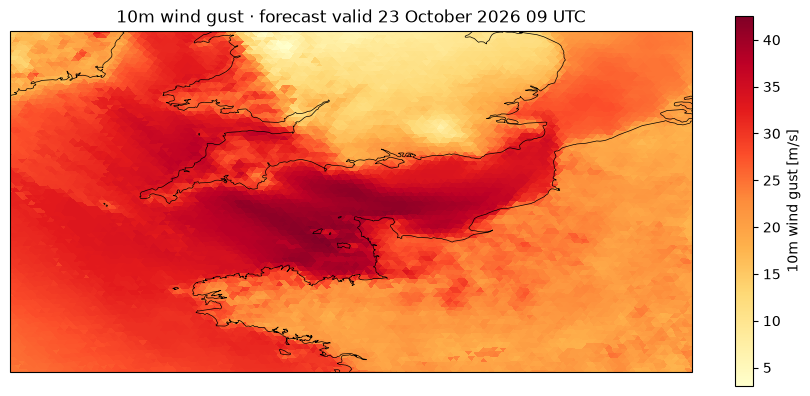

In [6]:
channel_cells = np.flatnonzero(
    (ds.longitude >= -8.1)
    & (ds.longitude <= 4.1)
    & (ds.latitude >= 46.9)
    & (ds.latitude <= 53.1)
)
gust = (
    ds["wind_gust_10m"]
    .sel(init_time="2026-10-22T00", lead_time="33h")
    .isel(cell=channel_cells)
    .load()
)

fig, ax = plt.subplots(figsize=(11, 6), subplot_kw={"projection": ccrs.PlateCarree()})
image = ax.tripcolor(
    node_lon, node_lat, triangles[channel_cells], facecolors=gust.values, cmap="YlOrRd"
)
ax.coastlines(linewidth=0.5)
ax.set_extent([-8, 4, 47, 53], crs=ccrs.PlateCarree())
ax.set_title("10m wind gust · forecast valid 23 October 2026 09 UTC")
fig.colorbar(image, ax=ax, label="10m wind gust [m/s]", shrink=0.8);

### How much rain did the forecast give Portugal during Storm Charles?

[Storm Charles crossed mainland Portugal on 11 November 2026](https://www.ipma.pt/pt/media/noticias/news.detail.jsp?f=Depressao_charles.html&y=2026). We can intersect the native triangles with mainland Portugal and weight the mean precipitation by each overlap's area. Natural Earth's country outline supplies the polygon; an equal-area projection gives the weights in square metres.

In [7]:
import geopandas as gpd
import shapely
import xarray as xr
from cartopy.io.shapereader import natural_earth

countries = gpd.read_file(
    natural_earth(resolution="50m", category="cultural", name="admin_0_countries")
)
portugal = countries.loc[countries.ADMIN == "Portugal", "geometry"].iloc[0]
mainland = max(portugal.geoms, key=lambda polygon: polygon.area)
country = gpd.GeoSeries([mainland], crs="EPSG:4326").to_crs("EPSG:3035").iloc[0]

faces = gpd.GeoSeries(
    shapely.polygons(np.stack([node_lon[triangles], node_lat[triangles]], axis=-1)),
    crs="EPSG:4326",
)
portugal_cells = faces.sindex.query(mainland, predicate="intersects")
weights = xr.DataArray(
    faces.iloc[portugal_cells].to_crs("EPSG:3035").intersection(country).area.values,
    dims="cell",
)

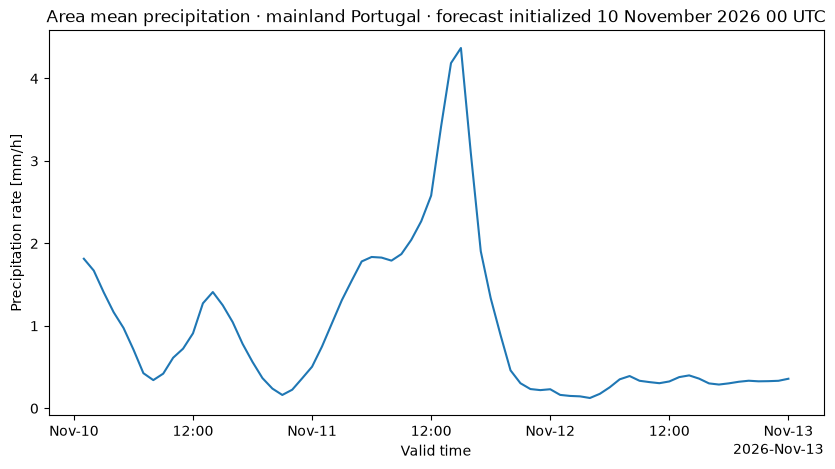

In [8]:
rain = (
    ds["precipitation_surface"]
    .sel(
        init_time="2026-11-10T00",
        lead_time=slice(np.timedelta64(1, "h"), np.timedelta64(72, "h")),
    )
    .isel(cell=portugal_cells)
    .load()
    * 3600
)
rain.attrs = {"long_name": "Precipitation rate", "units": "mm/h"}
mean_rain = rain.weighted(weights).mean("cell", keep_attrs=True)
mean_rain.plot(x="valid_time", figsize=(10, 5))
plt.title(
    "Area mean precipitation · mainland Portugal · forecast initialized 10 November 2026 00 UTC"
);

### How did temperatures change as Storm Charles passed Portugal?

A single 5-day forecast run spans the storm's passage. Here we compare noon on 10 and 12 November, regridding the intersecting cells onto a regular latitude/longitude grid with nearest neighbours.

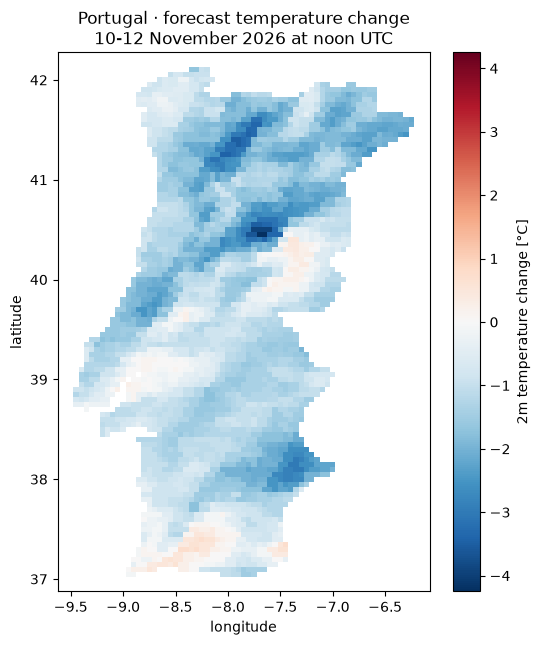

In [9]:
lats = np.arange(36.9, 42.25, 0.05)
lons = np.arange(-9.6, -6.05, 0.05)
source = ds.isel(cell=portugal_cells)
cell_lat = source.latitude.reset_coords(drop=True)
cell_lon = source.longitude.reset_coords(drop=True)
grid_lat = xr.DataArray(lats, coords={"latitude": lats})
grid_lon = xr.DataArray(lons, coords={"longitude": lons})
index = (
    (cell_lat - grid_lat) ** 2 + ((cell_lon - grid_lon) * np.cos(np.deg2rad(40))) ** 2
).argmin("cell")
land = index.copy(data=shapely.intersects_xy(mainland, lons[None, :], lats[:, None]))

temperature = (
    source["temperature_2m"]
    .sel(
        init_time="2026-11-10T00",
        lead_time=["12h", "60h"],
    )
    .load()
)
regular = temperature.drop_vars(["latitude", "longitude"]).isel(cell=index).where(land)
change = regular.isel(lead_time=1) - regular.isel(lead_time=0)
change.attrs = {"long_name": "2m temperature change", "units": "°C"}
change.plot(figsize=(6, 7), cmap="RdBu_r", center=0)
plt.title("Portugal · forecast temperature change\n10-12 November 2026 at noon UTC");

### How does cloud cover layer up as a front passes through?

ICON-EU reports cloud cover at low, medium, and high levels separately. This is useful for understanding cloud structure, not just total obscuration. Stacking these for a single location during a forecast run reveals the vertical signature of approaching fronts.

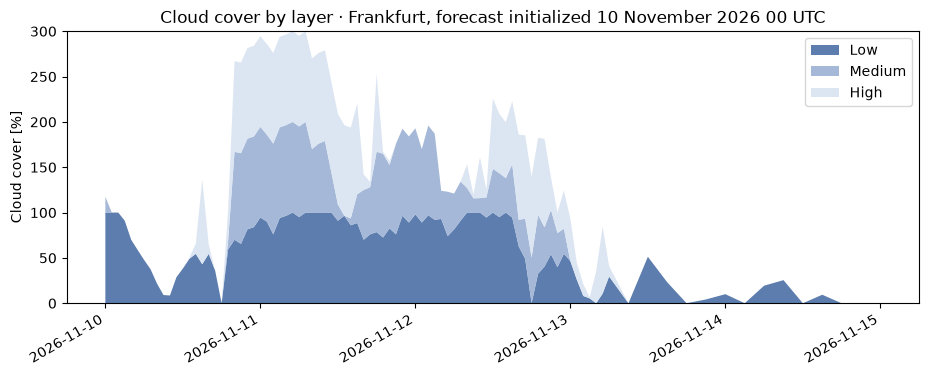

In [10]:
# Stack low / medium / high cloud cover for Frankfurt across a 5-day forecast.
lat, lon = 50.11, 8.68
distance = (ds.latitude - lat) ** 2 + (
    (ds.longitude - lon) * np.cos(np.deg2rad(lat))
) ** 2
plot_ds = ds.sel(init_time="2026-11-10T00").isel(cell=int(distance.argmin("cell")))
vt = plot_ds["valid_time"].values

fig, ax = plt.subplots(figsize=(11, 4))
ax.stackplot(
    vt,
    plot_ds["cloud_cover_low"].values,
    plot_ds["cloud_cover_medium"].values,
    plot_ds["cloud_cover_high"].values,
    labels=["Low", "Medium", "High"],
    colors=["#4a6fa5", "#9bb1d4", "#d9e3f1"],
    alpha=0.9,
)
ax.set_ylabel("Cloud cover [%]")
ax.set_title(
    "Cloud cover by layer · Frankfurt, forecast initialized 10 November 2026 00 UTC"
)
ax.set_ylim(0, 300)  # stacked sum; each layer independently 0-100
ax.legend(loc="upper right")
fig.autofmt_xdate()

### Animated map

Watch the forecast rain cross mainland Portugal during Storm Charles. This uses the same nearest-neighbour grid as the temperature map, sampling every three hours through 12 November.

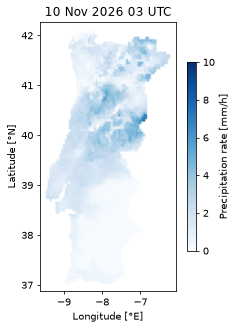

In [11]:
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

data = (
    rain.sel(lead_time=np.arange(3, 73, 3).astype("timedelta64[h]"))
    .drop_vars(["latitude", "longitude"])
    .isel(cell=index)
    .where(land)
)
fig, ax = plt.subplots(figsize=(4, 5), dpi=70)
rain_image = ax.imshow(
    data.isel(lead_time=0),
    cmap="Blues",
    vmin=0,
    vmax=10,
    origin="lower",
    extent=(lons[0] - 0.025, lons[-1] + 0.025, lats[0] - 0.025, lats[-1] + 0.025),
)
ax.set_aspect(1 / np.cos(np.deg2rad(40)))
ax.set_xlabel("Longitude [°E]")
ax.set_ylabel("Latitude [°N]")
fig.colorbar(rain_image, ax=ax, label="Precipitation rate [mm/h]", shrink=0.7)


def update(i: int) -> None:
    frame = data.isel(lead_time=i)
    rain_image.set_data(frame.values)
    ax.set_title(frame.valid_time.dt.strftime("%d %b %Y %H UTC").item())


anim = FuncAnimation(fig, update, frames=data.sizes["lead_time"], interval=180)
HTML(anim.to_jshtml())

### Community challenge

With ICON-EU's 6.5 km native grid, four daily forecasts, and Europe-wide coverage there are lots of interesting questions to explore. A few ideas to build on:

- **Orchard frost risk.** Map where the 5-day forecast minimum `temperature_2m` drops below 0°C across Europe's fruit belts (Loire, Rhine-Main, Emilia-Romagna, South Moravia). Which regions see the first autumn frost, and how far ahead does ICON-EU call it?
- **Do the European wind and solar fleets complement each other?** Construct simple proxies for national wind and solar generation from `wind_u_10m`/`wind_v_10m` and the direct and diffuse short-wave radiation fluxes. Use polygon intersections to average over each country. Do windy periods in northern Europe coincide with sunnier periods in the south?